# Modeling circular variables

Angular inputs (e.g. an animal's head direction) are common in neuroscience.

These variables are circular: -180° and +180° describe the same angle.
\
A standard B-spline basis treats these angles as opposite ends of a line. It does not require the fitted curve to match at the two ends, which can introduce an artificial discontinuity (a jump) in the tuning curve.
\
A cyclic B-spline basis accounts for the circular structure. Its basis functions wrap around from +180° to -180°, so the fitted curve has the same value and slope on both sides of this boundary.

In this notebook, we fit tuning curves for two simulated head direction cells using a cyclic B-spline basis. We then show why a cyclic B-spline basis is a better choice than a standard B-spline basis for circular inputs.

In [1]:
import jax
import nemos as nmo
import numpy as np
from example_data import make_head_direction_data
from example_plots import (
    hide_file_paths_in_warnings,
    plot_cyclic_and_noncyclic_smooths,
    plot_head_direction_tuning,
    set_plot_style,
)

from pgam_jax import GAM

jax.config.update("jax_enable_x64", True)
set_plot_style()
hide_file_paths_in_warnings()

## Simulate head direction cell activity

A head direction cell fires most strongly when the animal faces its preferred direction $\mu$.
\
We simulate two cells, recorded at the same time.
We draw 1000 head directions $\theta$ uniformly around the circle, and one spike count $y$ per cell for each:

$$\lambda(\theta) = r_0 + r_{\mathrm{peak}} \exp\big(\kappa\,(\cos(\theta - \mu) - 1)\big)$$

$$y \sim \mathrm{Poisson}(\lambda(\theta))$$

* $r_0 = 0.05$ is the baseline expected spike count.
* $r_{\mathrm{peak}} = 0.6$ is the increase in expected spike count at the preferred direction.
* $\kappa$ sets the width of the peak. A larger $\kappa$ gives a narrower peak.

The peak has the shape of a von Mises distribution, the circular version of a Gaussian.
\
We simulate one cell with sharp tuning and one with wide tuning, with the peak of the wide cell crossing the wrap point at ±180°:

<table style="width: auto; margin-left: 0">
  <tr><th>Cell</th><th>Preferred direction <i>μ</i></th><th><i>κ</i></th></tr>
  <tr><td>sharp</td><td>90°</td><td>8</td></tr>
  <tr><td>wide</td><td>160°</td><td>1.5</td></tr>
</table>


In [2]:
data = make_head_direction_data()

for name in ["angle", "spikes", "angle_grid", "true_count_grid"]:
    label = f"Shape of data.{name}:"
    print(f"{label:<33}{getattr(data, name).shape}")
print()
for column, cell in enumerate(data.cells):
    print(f"Spikes of the {cell.name} cell: {data.spikes[:, column].sum()}")

Shape of data.angle:             (1000,)
Shape of data.spikes:            (1000, 2)
Shape of data.angle_grid:        (361,)
Shape of data.true_count_grid:   (361, 2)

Spikes of the sharp cell: 132
Spikes of the wide cell: 302


We first get a rough estimate of each cell’s tuning curve by averaging the spike counts within each direction bin.
The top row plots these estimates against head direction, with a tick marking the angle of each spike.
The bottom row shows the same curves on a circle, making it clear that the wide cell’s peak continues across ±180°.

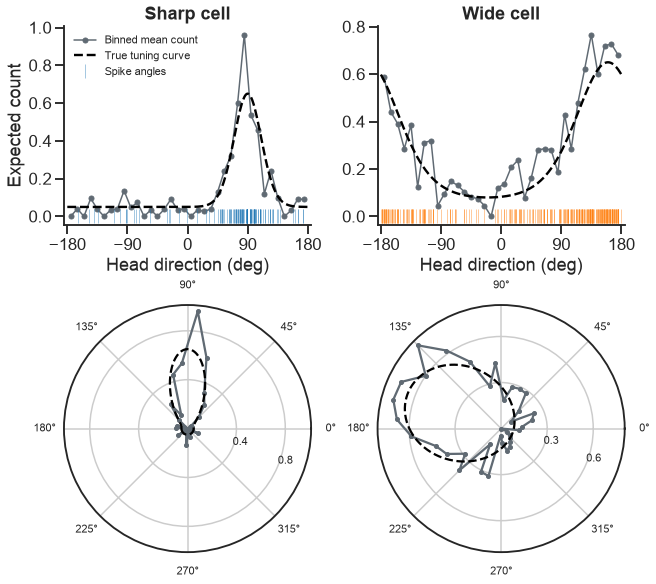

In [3]:
fig, ax = plot_head_direction_tuning(data)

## Fit a GAM with a cyclic basis

`CyclicBSplineEval` takes `n_basis_funcs`, `order`, and `bounds`, like `BSplineEval`.
The `bounds` must cover exactly one turn of the circle: $(-\pi, \pi)$ here, or $(0, 2\pi)$, or $(-180, 180)$ for angles in degrees.

**WARNING:** On nemos <= 0.2.9, wrap the angles into the `bounds` before the fit.
On these versions, an angle outside the `bounds` gives a row of NaN features.
With the default `nan_handling="zero"`, the GAM replaces these NaNs with zeros and gives no warning.
Later versions will wrap these angles automatically.
\
For the bounds $(-\pi, \pi)$, use `angle = (angle + np.pi) % (2 * np.pi) - np.pi`.

In [4]:
N_BASIS = 12

gams = []
for column in range(len(data.cells)):
    basis = nmo.basis.CyclicBSplineEval(
        N_BASIS,
        bounds=(-np.pi, np.pi),
        label="head direction",
    )
    gam = GAM(basis, use_scipy=True)
    gam.fit((data.angle,), data.spikes[:, column])
    gams.append(gam)

## GAM recovers the true tuning curves

`gam.predict` gives the expected spike count at each angle of the grid.

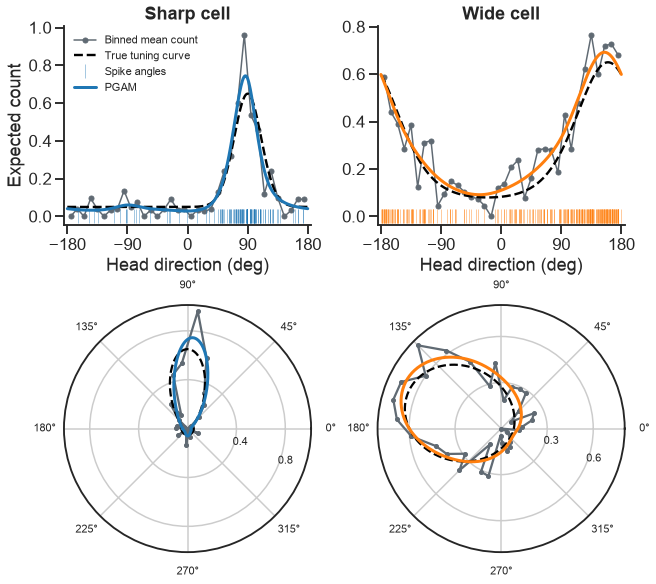

In [5]:
fitted_count_grid = np.stack(
    [gam.predict((data.angle_grid,)) for gam in gams],
    axis=1,
)

fig, ax = plot_head_direction_tuning(data, fitted_count_grid)

The effective degrees of freedom (EDF) measure the flexibility of the fitted curve. The sharp cell’s fit has higher EDF, allowing it to capture the narrower peak.

In [6]:
for cell, gam in zip(data.cells, gams):
    print(f"{cell.name:>5} cell, EDF: {float(gam.edf_):.1f}")

sharp cell, EDF: 7.5
 wide cell, EDF: 5.3


## Compare with a standard B-spline basis

We fit the wide cell again using a standard B-spline basis with the same number of basis functions.
We then use `gam.smooth_compute` to compare each fitted smooth’s contribution to the log expected spike count, along with its pointwise 95% confidence band.


*Note: Unlike the earlier plots of expected spike counts, this comparison shows the smooths on a log scale. The smooths are centered on the plotting grid, so the comparison focuses on their shape.*

In [7]:
wide_column = 1  # the wide cell, with its peak at 160°

noncyclic_basis = nmo.basis.BSplineEval(
    N_BASIS,
    bounds=(-np.pi, np.pi),
    label="head direction",
)
noncyclic_gam = GAM(noncyclic_basis, use_scipy=True)
noncyclic_gam.fit((data.angle,), data.spikes[:, wide_column])

cyclic_smooth = gams[wide_column].smooth_compute(data.angle_grid, "head direction")
noncyclic_smooth = noncyclic_gam.smooth_compute(data.angle_grid, "head direction")

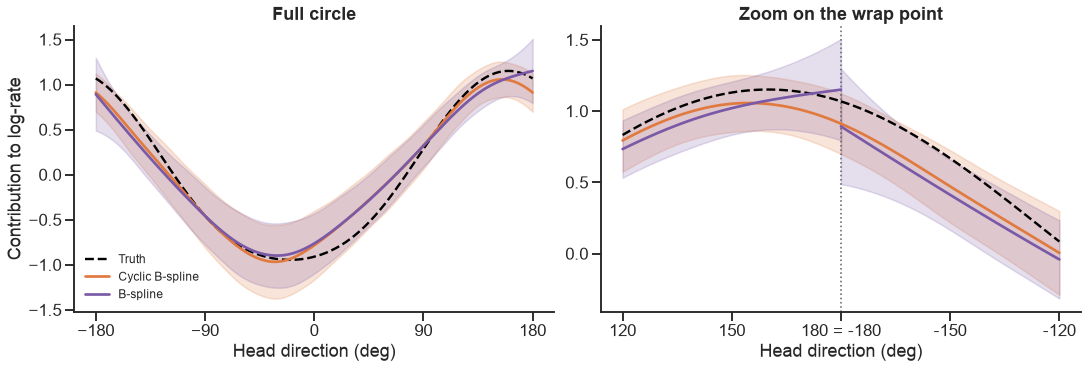

In [8]:
true_log_rate = np.log(data.true_count_grid[:, wide_column])

fig = plot_cyclic_and_noncyclic_smooths(
    data.angle_grid, true_log_rate, cyclic_smooth, noncyclic_smooth
)

The right panel centers the view on ±180°, bringing the two ends of the left panel together.

- The cyclic smooth joins continuously across this boundary. Data on both sides help constrain the fit.
- The standard B-spline smooth does not have to match at the boundary. Here, this produces a jump and wider confidence bands near ±180°.

A cyclic basis preserves the continuity we expect when modeling tuning to a circular variable.